In [23]:
#Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [24]:
#Step 2: Load Dataset
df = pd.read_csv("C:/Users/anshu/Downloads/stock_data.csv")

df.head()

,Date,Open,High,Low,Close,Volume,Name
0,1/3/2006,39.69,41.22,38.79,40.91,24232729,AABA
1,1/4/2006,41.22,41.90,40.77,40.97,20553479,AABA
2,1/5/2006,40.93,41.73,40.85,41.53,12829610,AABA
3,1/6/2006,42.88,43.57,42.80,43.21,29422828,AABA
4,1/9/2006,43.10,43.66,42.82,43.42,16268338,AABA


In [25]:
data = df[['Close']].values

In [26]:
#Step 3: Feature Scaling
scaler = MinMaxScaler(feature_range=(0,1))
scaled_data = scaler.fit_transform(data)

In [27]:
#Step 4: Create Training Data
X_train = []
y_train = []

for i in range(60, len(scaled_data)):
    X_train.append(scaled_data[i-60:i, 0])
    y_train.append(scaled_data[i, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)

X_train = np.reshape(
    X_train,
    (X_train.shape[0], X_train.shape[1], 1)
)

print(X_train.shape)

(2959, 60, 1)


In [28]:
#Step 5: Build GRU Model
model = Sequential()

model.add(
    GRU(
        units=50,
        return_sequences=True,
        input_shape=(X_train.shape[1],1)
    )
)

model.add(Dropout(0.2))

model.add(
    GRU(
        units=50,
        return_sequences=True
    )
)

model.add(Dropout(0.2))

model.add(
    GRU(
        units=50
    )
)

model.add(Dropout(0.2))

model.add(Dense(units=1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 gru_6 (GRU)                 (None, 60, 50)            7950      
                                                                 
 dropout_6 (Dropout)         (None, 60, 50)            0         
                                                                 
 gru_7 (GRU)                 (None, 60, 50)            15300     
                                                                 
 dropout_7 (Dropout)         (None, 60, 50)            0         
                                                                 
 gru_8 (GRU)                 (None, 50)                15300     
                                                                 
 dropout_8 (Dropout)         (None, 50)                0         
                                                                 
 dense_2 (Dense)             (None, 1)                

In [29]:
#Step 6: Train the Model
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32
)

Epoch 1/50
93/93 [==============================] - 20s 72ms/step - loss: 0.0093
Epoch 2/50
93/93 [==============================] - 9s 100ms/step - loss: 0.0020
Epoch 3/50
93/93 [==============================] - 9s 99ms/step - loss: 0.0015
Epoch 4/50
93/93 [==============================] - 10s 108ms/step - loss: 0.0014
Epoch 5/50
93/93 [==============================] - 11s 114ms/step - loss: 0.0014
Epoch 6/50
93/93 [==============================] - 13s 144ms/step - loss: 0.0012
Epoch 7/50
93/93 [==============================] - 9s 102ms/step - loss: 0.0012
Epoch 8/50
93/93 [==============================] - 9s 99ms/step - loss: 0.0013
Epoch 9/50
93/93 [==============================] - 10s 102ms/step - loss: 0.0012
Epoch 10/50
93/93 [==============================] - 8s 89ms/step - loss: 9.6740e-04
Epoch 11/50
93/93 [==============================] - 9s 93ms/step - loss: 9.3698e-04
Epoch 12/50
93/93 [==============================] - 10s 102ms/step - loss: 0.0010
Epoch 13/50
93/9

In [30]:
#Step 7: Predict Stock Price
predicted_price = model.predict(X_train)

predicted_price = scaler.inverse_transform(
    predicted_price
)

real_price = scaler.inverse_transform(
    y_train.reshape(-1,1)
)

93/93 [==============================] - 4s 21ms/step


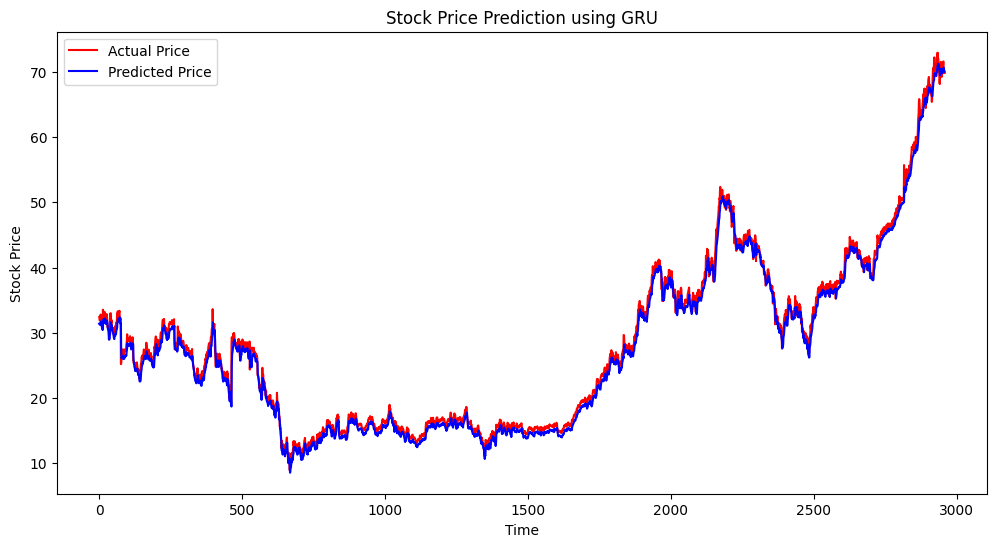

In [31]:
#Step 8: Visualize Results
plt.figure(figsize=(12,6))

plt.plot(
    real_price,
    color='red',
    label='Actual Price'
)

plt.plot(
    predicted_price,
    color='blue',
    label='Predicted Price'
)

plt.title('Stock Price Prediction using GRU')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()

plt.show()

In [32]:
#Step 9: Predict Next Day Price
last_60_days = scaled_data[-60:]

X_test = np.array([last_60_days])

X_test = np.reshape(
    X_test,
    (1,60,1)
)

next_day_price = model.predict(X_test)

next_day_price = scaler.inverse_transform(
    next_day_price
)

print("Next Day Predicted Price:", next_day_price[0][0])

1/1 [==============================] - 0s 52ms/step
Next Day Predicted Price: 69.993004


In [15]:
data = df[['Open']].values

In [16]:
#Step 3: Feature Scaling
scaler = MinMaxScaler(feature_range=(0,1))
scaled_data = scaler.fit_transform(data)

In [17]:
#Step 4: Create Training Data
X_train = []
y_train = []

for i in range(60, len(scaled_data)):
    X_train.append(scaled_data[i-60:i, 0])
    y_train.append(scaled_data[i, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)

X_train = np.reshape(
    X_train,
    (X_train.shape[0], X_train.shape[1], 1)
)

print(X_train.shape)

(2959, 60, 1)


In [18]:
#Step 5: Build GRU Model
model = Sequential()

model.add(
    GRU(
        units=50,
        return_sequences=True,
        input_shape=(X_train.shape[1],1)
    )
)

model.add(Dropout(0.2))

model.add(
    GRU(
        units=50,
        return_sequences=True
    )
)

model.add(Dropout(0.2))

model.add(
    GRU(
        units=50
    )
)

model.add(Dropout(0.2))

model.add(Dense(units=1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 gru_3 (GRU)                 (None, 60, 50)            7950      
                                                                 
 dropout_3 (Dropout)         (None, 60, 50)            0         
                                                                 
 gru_4 (GRU)                 (None, 60, 50)            15300     
                                                                 
 dropout_4 (Dropout)         (None, 60, 50)            0         
                                                                 
 gru_5 (GRU)                 (None, 50)                15300     
                                                                 
 dropout_5 (Dropout)         (None, 50)                0         
                                                                 
 dense_1 (Dense)             (None, 1)                

In [19]:
#Step 6: Train the Model
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32
)

Epoch 1/50
93/93 [==============================] - 13s 61ms/step - loss: 0.0082
Epoch 2/50
93/93 [==============================] - 6s 60ms/step - loss: 0.0017
Epoch 3/50
93/93 [==============================] - 6s 61ms/step - loss: 0.0017
Epoch 4/50
93/93 [==============================] - 6s 62ms/step - loss: 0.0014
Epoch 5/50
93/93 [==============================] - 5s 58ms/step - loss: 0.0013
Epoch 6/50
93/93 [==============================] - 6s 64ms/step - loss: 0.0013
Epoch 7/50
93/93 [==============================] - 6s 65ms/step - loss: 0.0012
Epoch 8/50
93/93 [==============================] - 6s 62ms/step - loss: 0.0013
Epoch 9/50
93/93 [==============================] - 6s 65ms/step - loss: 0.0010
Epoch 10/50
93/93 [==============================] - 6s 63ms/step - loss: 0.0012
Epoch 11/50
93/93 [==============================] - 6s 62ms/step - loss: 9.5404e-04
Epoch 12/50
93/93 [==============================] - 6s 65ms/step - loss: 0.0010
Epoch 13/50
93/93 [=============

In [20]:
#Step 7: Predict Stock Price
predicted_price = model.predict(X_train)

predicted_price = scaler.inverse_transform(
    predicted_price
)

real_price = scaler.inverse_transform(
    y_train.reshape(-1,1)
)

93/93 [==============================] - 3s 16ms/step


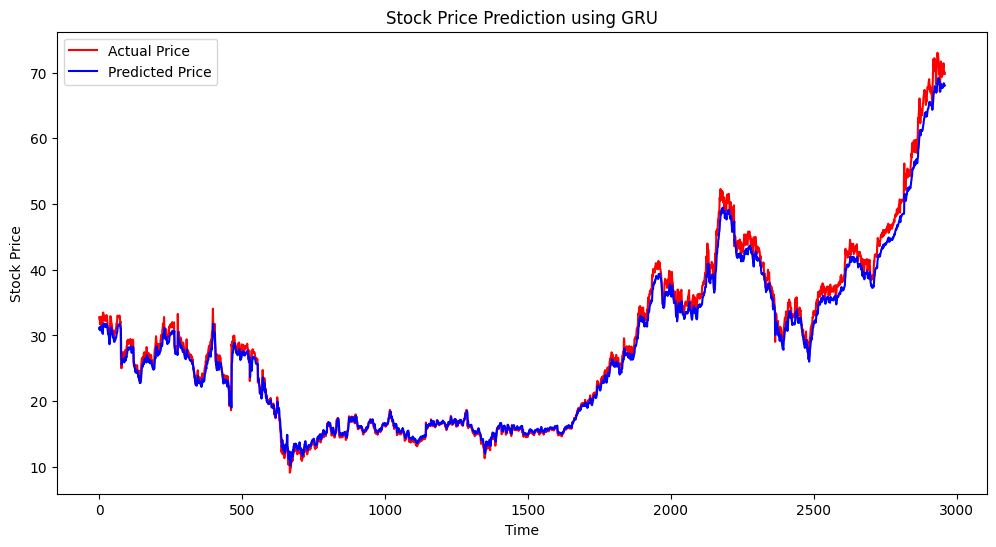

In [21]:
#Step 8: Visualize Results
plt.figure(figsize=(12,6))

plt.plot(
    real_price,
    color='red',
    label='Actual Price'
)

plt.plot(
    predicted_price,
    color='blue',
    label='Predicted Price'
)

plt.title('Stock Price Prediction using GRU')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()

plt.show()

In [22]:
#Step 9: Predict Next Day Price
last_60_days = scaled_data[-60:]

X_test = np.array([last_60_days])

X_test = np.reshape(
    X_test,
    (1,60,1)
)

next_day_price = model.predict(X_test)

next_day_price = scaler.inverse_transform(
    next_day_price
)

print("Next Day Predicted Price:", next_day_price[0][0])

1/1 [==============================] - 0s 46ms/step
Next Day Predicted Price: 67.8644
